# 02 — Model Evaluation: Champion LightGBM

**Goal:** go beyond one headline number and understand *where* the production model (the current champion, `models/champion/`) is strong and weak, on the untouched **test window (Oct–Dec 2024)**.

In [1]:
import json
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from taxi_demand.config import load_config, resolve
from taxi_demand.training.metrics import all_metrics, wape

plt.rcParams.update({"figure.figsize": (11, 3.6), "figure.dpi": 80, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

cfg = load_config()
feats, cats = cfg["training"]["features"], cfg["training"]["categorical"]
df = pd.read_parquet(resolve("data/processed/features.parquet"))
test = df[df.hour >= cfg["training"]["valid_end"]].copy()
zones = pd.read_csv(resolve("data/raw/taxi_zone_lookup.csv")).set_index("LocationID")["Zone"]

booster = lgb.Booster(model_file=str(resolve("models/champion/model.txt")))
meta = json.loads(resolve("models/champion/metadata.json").read_text())
X = test[feats].copy()
for c in cats:
    X[c] = X[c].astype("category")
test["pred"] = np.clip(booster.predict(X), 0, None)
print(f"champion: v{meta['version']} | test rows: {len(test):,} | "
      f"{test.hour.min():%Y-%m-%d} -> {test.hour.max():%Y-%m-%d}")

champion: v1 | test rows: 580,704 | 2024-10-01 -> 2024-12-31


## 1. Headline: model vs. baselines

In [2]:
rows = {
    "naive: last hour (lag_1)": test["lag_1"],
    "seasonal naive: last week (lag_168)": test["lag_168"],
    "LightGBM champion": test["pred"],
}
table = pd.DataFrame({k: all_metrics(test["pickups"], v) for k, v in rows.items()}).T.round(4)
table["WAPE vs best baseline"] = (1 - table["wape"] / table["wape"].iloc[:2].min()).map("{:+.1%}".format)
print(table.to_string())

                                        mae     rmse    wape WAPE vs best baseline
naive: last hour (lag_1)             4.8261  15.9834  0.2625                 +0.0%
seasonal naive: last week (lag_168)  5.0549  18.7698  0.2749                 -4.7%
LightGBM champion                    2.7234   8.6880  0.1481                +43.6%


## 2. Actual vs. predicted: one week in three busy zones

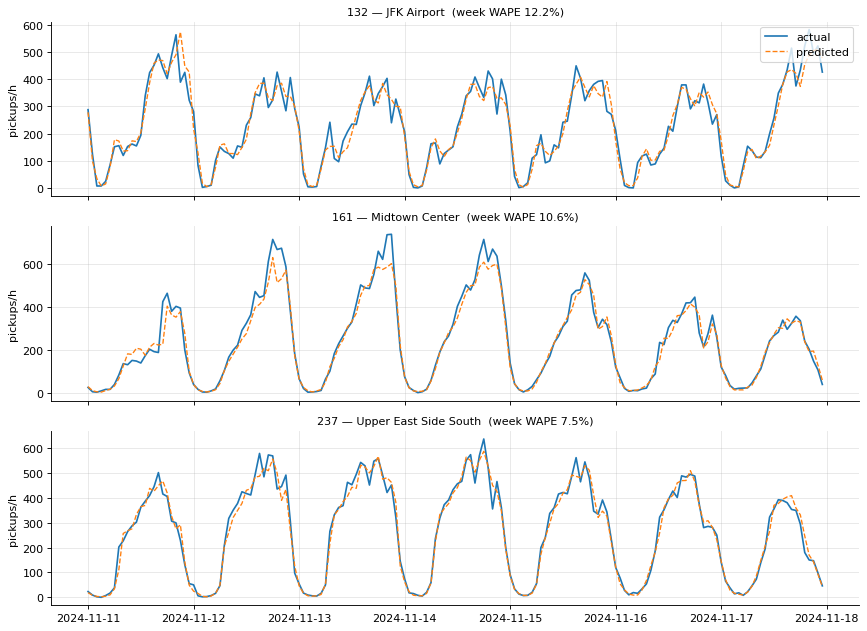

In [3]:
week = (test.hour >= "2024-11-11") & (test.hour < "2024-11-18")
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, z in zip(axes, [132, 161, 237]):
    d = test[week & (test.zone_id == z)]
    ax.plot(d.hour, d.pickups, lw=1.5, label="actual")
    ax.plot(d.hour, d.pred, lw=1.2, ls="--", label="predicted")
    ax.set_title(f"{z} — {zones[z]}  (week WAPE {wape(d.pickups, d.pred):.1%})", fontsize=10)
    ax.set_ylabel("pickups/h")
axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

## 3. Where is the model weak? Error by hour of day
WAPE per hour of day, for the model and the best baseline.

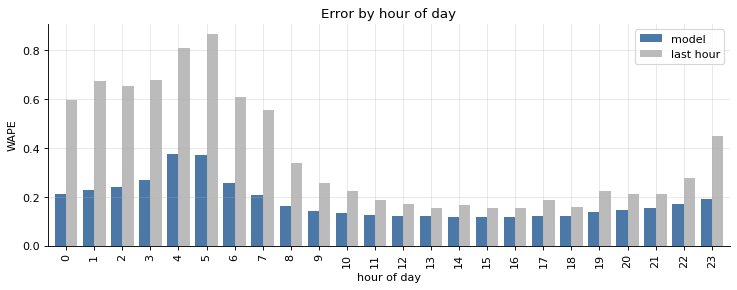

worst hour for the model: 04:00 (WAPE 37.4%) | best: 16:00 (WAPE 11.6%)


In [4]:
by_hour = test.groupby(test.hour.dt.hour).apply(
    lambda g: pd.Series({"model": wape(g.pickups, g.pred), "last hour": wape(g.pickups, g.lag_1)}),
    include_groups=False)
ax = by_hour.plot(kind="bar", width=0.8, color=["#4C78A8", "#BBBBBB"])
ax.set_xlabel("hour of day"); ax.set_ylabel("WAPE"); ax.set_title("Error by hour of day")
plt.show()
print(f"worst hour for the model: {by_hour.model.idxmax():02d}:00 (WAPE {by_hour.model.max():.1%}) | "
      f"best: {by_hour.model.idxmin():02d}:00 (WAPE {by_hour.model.min():.1%})")

## 4. Error by zone size
Zones split into groups by average demand. Relative error is expected to be higher in quiet zones, where a miss of 1–2 pickups is a large percentage.

In [5]:
zone_mean = test.groupby("zone_id")["pickups"].mean()
bins = [-0.01, 1, 10, 50, np.inf]
labels = ["<1/h (quiet)", "1-10/h", "10-50/h", ">=50/h (busy)"]
test["size"] = test.zone_id.map(pd.cut(zone_mean, bins=bins, labels=labels))
by_size = test.groupby("size", observed=True).apply(lambda g: pd.Series({
    "zones": g.zone_id.nunique(),
    "share of pickups": g.pickups.sum() / test.pickups.sum(),
    "model WAPE": wape(g.pickups, g.pred),
    "baseline WAPE": wape(g.pickups, g.lag_1),
    "model MAE": (g.pickups - g.pred).abs().mean(),
}), include_groups=False)
print(by_size.to_string(formatters={"zones": "{:.0f}".format, "share of pickups": "{:.1%}".format,
      "model WAPE": "{:.1%}".format, "baseline WAPE": "{:.1%}".format, "model MAE": "{:.2f}".format}))

              zones share of pickups model WAPE baseline WAPE model MAE
size                                                                   
<1/h (quiet)    153             0.9%     111.3%        129.2%      0.32
1-10/h           58             3.3%      50.2%         66.0%      1.37
10-50/h          16             8.9%      19.0%         29.8%      5.13
>=50/h (busy)    36            86.9%      12.0%         23.3%     14.06


## 5. What drives the predictions? Feature importance (gain)

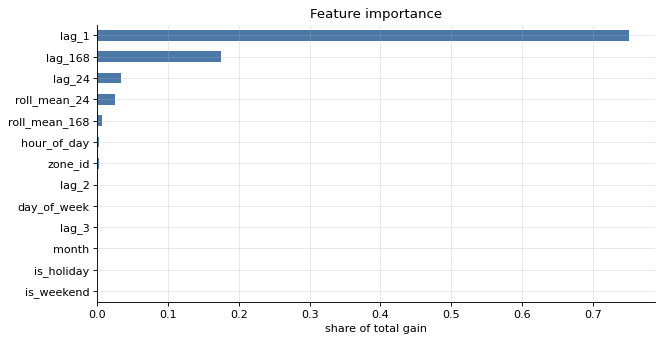

top 3: lag_1 (75%), lag_168 (17%), lag_24 (3%)


In [6]:
imp = pd.Series(booster.feature_importance("gain"), index=booster.feature_name())
imp = (imp / imp.sum()).sort_values()
ax = imp.plot(kind="barh", color="#4C78A8", figsize=(9, 4.5))
ax.set_xlabel("share of total gain"); ax.set_title("Feature importance")
plt.show()
print("top 3:", ", ".join(f"{k} ({v:.0%})" for k, v in imp.sort_values(ascending=False).head(3).items()))

## 6. Bias check: does the model systematically over- or under-predict?
Mean (predicted − actual) by hour. A good model hovers around zero; a consistent offset would suggest a missing feature.

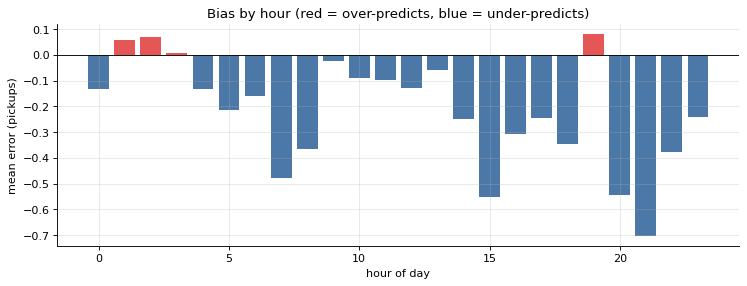

overall bias: -0.218 pickups per zone-hour (total predicted / actual = 0.988)


In [7]:
bias = (test.pred - test.pickups).groupby(test.hour.dt.hour).mean()
fig, ax = plt.subplots()
ax.bar(bias.index, bias.values, color=np.where(bias > 0, "#E45756", "#4C78A8"))
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("hour of day"); ax.set_ylabel("mean error (pickups)")
ax.set_title("Bias by hour (red = over-predicts, blue = under-predicts)")
plt.show()
print(f"overall bias: {(test.pred - test.pickups).mean():+.3f} pickups per zone-hour "
      f"(total predicted / actual = {test.pred.sum() / test.pickups.sum():.3f})")

## 7. Hardest zones (among those with meaningful demand)

In [8]:
zz = test.groupby("zone_id").apply(lambda g: pd.Series({
    "avg pickups/h": g.pickups.mean(), "WAPE": wape(g.pickups, g.pred)}), include_groups=False)
zz = zz[zz["avg pickups/h"] >= 10].sort_values("WAPE", ascending=False).head(8)
zz.insert(0, "zone", zz.index.map(zones))
print(zz.round({"avg pickups/h": 1, "WAPE": 3}).to_string())

                             zone  avg pickups/h   WAPE
zone_id                                                
74              East Harlem North           11.6  0.279
70                  East Elmhurst           17.4  0.278
41                 Central Harlem           13.7  0.274
24                   Bloomingdale           12.1  0.254
88       Financial District South           14.3  0.242
50                   Clinton West           27.8  0.227
166           Morningside Heights           23.2  0.210
87       Financial District North           26.9  0.200


## Key takeaways

1. **The model clearly earns its place.** WAPE 0.148 vs 0.263 for the best baseline (**−43.6% error**), and RMSE nearly halved (8.7 vs 16.0), so it also avoids the large misses that naive forecasts make at demand turning points.
2. **It's accurate where the business value is.** The 36 busy zones (≥50 pickups/h) carry **87% of all demand**, and there the model's WAPE is **12.0%** (baseline 23.3%). In the 153 quiet zones WAPE looks huge (111%), but the average miss is only **0.32 pickups/hour**, so percentages are misleading at near-zero volume.
3. **Weakest at night.** Error peaks around **4 am (WAPE 37%)** when volumes are tiny and noisy, and is lowest in the afternoon (**16:00, 11.6%**).
4. **Recent history dominates.** `lag_1` (75% of gain) and `lag_168` (17%) drive predictions, consistent with the EDA autocorrelation. Calendar features add the remaining refinements.
5. **Slight under-prediction (−1.2% overall).** That fits the upward demand trend found in the EDA (+7% YoY): a model trained on older data lags a growing market. That's an argument for **regular retraining**, plus a candidate improvement (a trend feature or a longer rolling mean).
6. **Hardest mid-size zones** are mostly residential or mixed areas (East Harlem, Central Harlem, East Elmhurst, Financial District). Their demand depends on local events and weather that the model can't see. **Weather and event features** are the obvious next step.
